# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


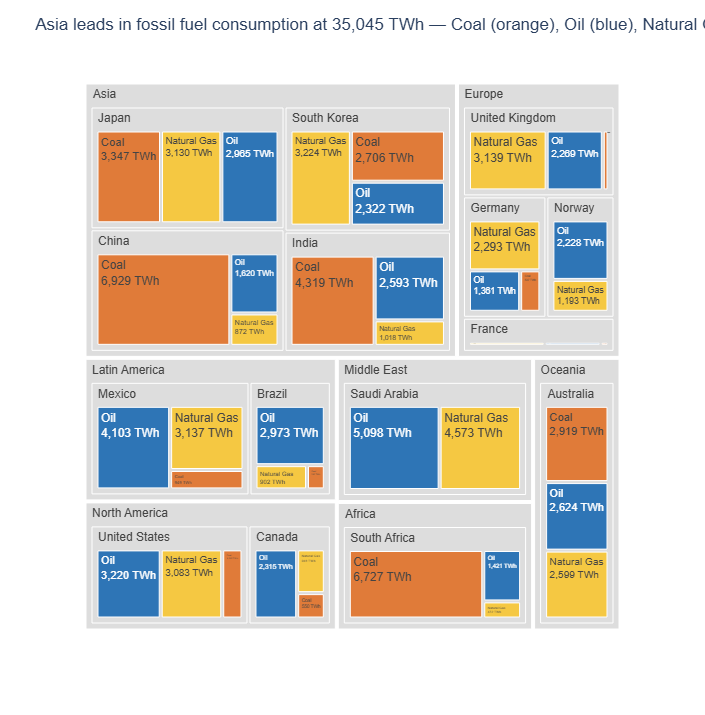

In [3]:
# Task 1
# YOUR CODE HERE
# Filter to fossil sources only
df_fossil = df.loc[df['Source_Type'] == 'Fossil']

# CVD-safe colour mapping for fossil sources
fossil_colors = {
    'Coal': '#E07B39',         # orange — the accent reused in Task 3
    'Oil': '#2E75B6',          # blue
    'Natural Gas': '#F5C842',  # yellow — separated from orange by lightness
}

# Create treemap
fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    labels={'TWh': 'Energy (TWh)'},
    height=700, width=1100,
    template='plotly_white'
)

# Customisation
fig.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh'
)

# Calculate which region is most fossil-dependent
regional_fossil = df_fossil.groupby('Region')['TWh'].sum().sort_values(ascending=False)
top_region = regional_fossil.index[0]
top_value = regional_fossil.iloc[0]

fig.update_layout(
    title=f'{top_region} leads in fossil fuel consumption at {top_value:,.0f} TWh — Coal (orange), Oil (blue), Natural Gas (yellow)',
    font=dict(family='Arial', size=12),
)

# Grey out parent nodes (Region and Country level)
fig.data[0].marker.colors = [
    c if c in fossil_colors.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

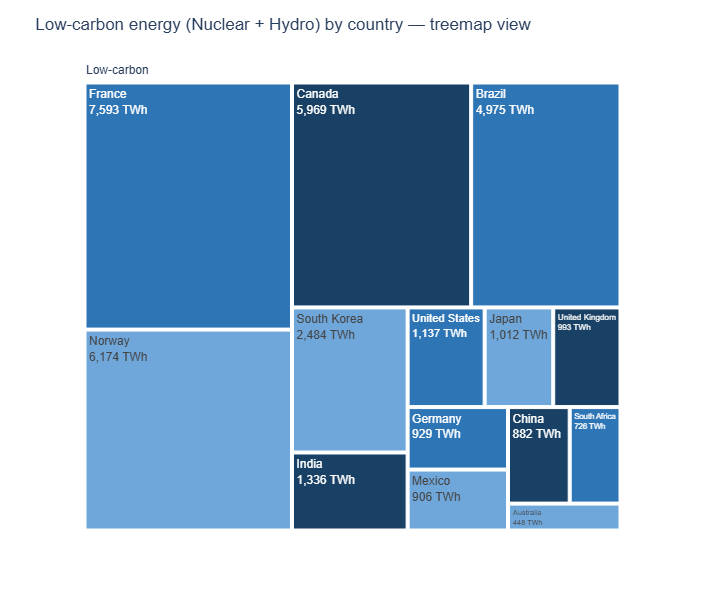

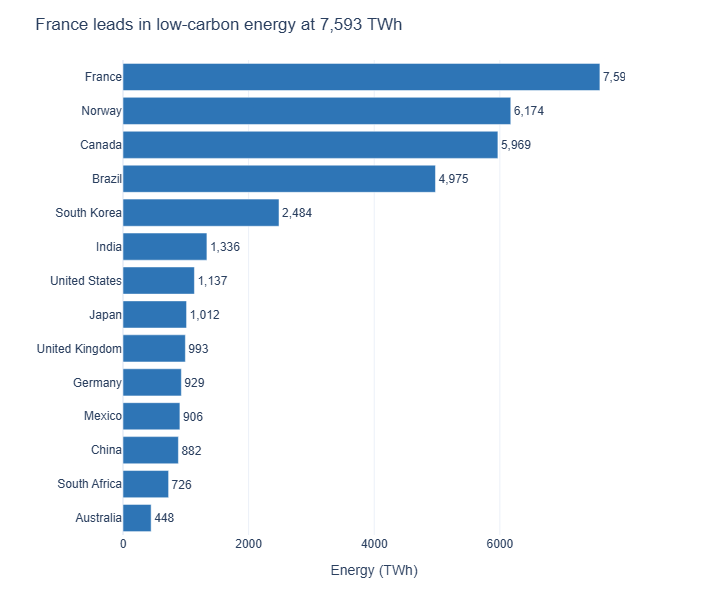

In [4]:
# Task 2 — charts
# YOUR CODE HERE
# Filter to low-carbon sources and aggregate by country
df_lowcarbon = df.loc[df['Source_Type'] == 'Low-carbon']
lowcarbon_by_country = df_lowcarbon.groupby('Country')['TWh'].sum().reset_index()

# Sort by TWh to find the leader
lowcarbon_by_country = lowcarbon_by_country.sort_values('TWh', ascending=False)
top_country = lowcarbon_by_country.iloc[0]['Country']
top_twh = lowcarbon_by_country.iloc[0]['TWh']

# --- Treemap ---
# Add dummy root node for single-level hierarchy
lowcarbon_by_country['All'] = 'Low-carbon'

fig_tree = px.treemap(
    lowcarbon_by_country,
    path=['All', 'Country'],
    values='TWh',
    color_discrete_sequence=['#2E75B6'],
    height=600, width=1000,
    template='plotly_white'
)

fig_tree.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh'
)

fig_tree.update_layout(
    title='Low-carbon energy (Nuclear + Hydro) by country — treemap view',
    font=dict(family='Arial', size=12),
)

fig_tree.show()

# --- Horizontal Bar Chart ---
fig_bar = px.bar(
    lowcarbon_by_country,
    x='TWh', y='Country',
    orientation='h',
    color_discrete_sequence=['#2E75B6'],
    labels={'TWh': 'Energy (TWh)'},
    height=600, width=1000,
    template='plotly_white'
)

fig_bar.update_traces(
    texttemplate='%{x:,.0f}',
    textposition='outside',
)

fig_bar.update_layout(
    title=f'{top_country} leads in low-carbon energy at {top_twh:,.0f} TWh',
    font=dict(family='Arial', size=12),
    yaxis=dict(title='', autorange='reversed'),  # reversed to show highest at top
    xaxis=dict(title='Energy (TWh)'),
    showlegend=False
)

fig_bar.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The bar chart. All the bars start from the same baseline, so you just compare lengths, and that's easy to do by eye. The treemap uses area instead, which is much harder to judge. For example, Norway (6,174 TWh) and Canada (5,969 TWh) look almost the same size in the treemap, but in the bar chart you can see right away which one is longer.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

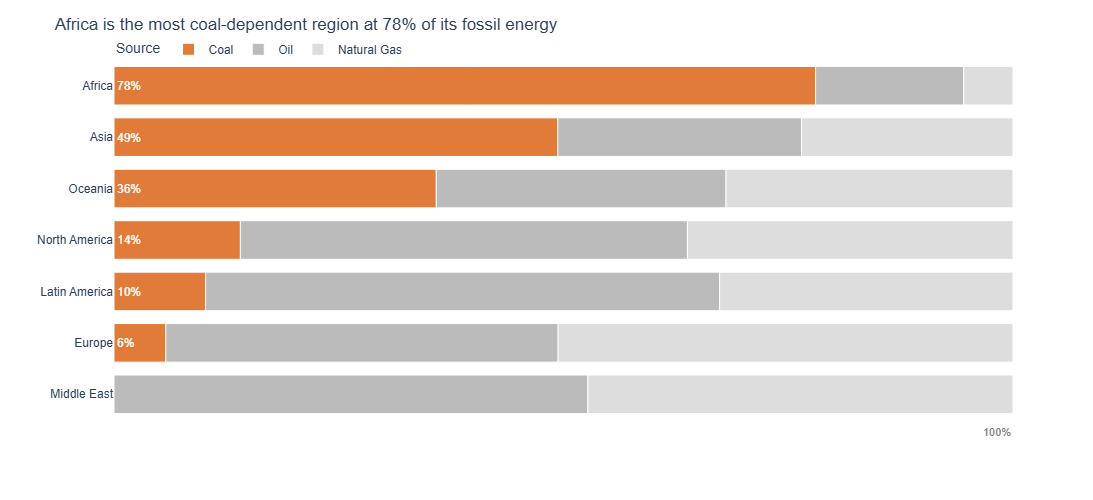

In [16]:
# Task 3
# YOUR CODE HERE
# Reuse fossil data from Task 1
# Aggregate TWh by Region × Source
# unstack/stack with fill_value=0 keeps regions with no coal (Middle East) as an explicit 0
regional_fossil = (df_fossil.groupby(['Region', 'Source'])['TWh'].sum()
                   .unstack(fill_value=0).stack()
                   .rename('TWh').reset_index())

# Convert to shares of each region's fossil total
regional_fossil['Share'] = (regional_fossil['TWh'] / 
                             regional_fossil.groupby('Region')['TWh'].transform('sum'))

# Calculate coal share per region for sorting
coal_shares = regional_fossil.loc[regional_fossil['Source'] == 'Coal'].set_index('Region')['Share']
region_order = coal_shares.sort_values(ascending=False).index.tolist()

# Find the top coal-dependent region
top_coal_region = region_order[0]
top_coal_share = coal_shares[top_coal_region]

# Prepare labels - only show percentage on Coal segments
regional_fossil['Label'] = np.where(
    regional_fossil['Source'] == 'Coal',
    regional_fossil['Share'].map('{:.0%}'.format),
    ''
)

# Color mapping: Coal in color (same as Task 1), Oil and Natural Gas in greys
coal_accent_colors = {
    'Coal': '#E07B39',         # orange — the accent (same as Task 1)
    'Oil': '#BBBBBB',          # mid grey
    'Natural Gas': '#DDDDDD',  # light grey
}

# Create 100% stacked horizontal bar chart
fig = px.bar(
    regional_fossil,
    x='Share', y='Region',
    color='Source',
    text='Label',
    color_discrete_map=coal_accent_colors,
    category_orders={
        'Region': region_order,
        'Source': ['Coal', 'Oil', 'Natural Gas']  # Coal on baseline
    },
    labels={'Share': 'Share of fossil energy'},
    height=500, width=1000,
    template='plotly_white'
)

# Customisation
fig.update_traces(
    textposition='inside',
    insidetextanchor='start',
    textfont=dict(color='white', size=12, family='Arial'),
    marker_line_color='white',
    marker_line_width=1
)

fig.update_layout(
    title=f'{top_coal_region} is the most coal-dependent region at {top_coal_share:.0%} of its fossil energy',
    font=dict(family='Arial', size=12),
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title=''),
    legend=dict(orientation='h', x=0, y=1.07),
    bargap=0.25
)

# Mark the 100% end of scale
fig.add_annotation(
    x=1, y=0,
    xref='x', yref='paper',
    xanchor='right', yanchor='top',
    yshift=-4,
    text='100%',
    showarrow=False,
    font=dict(size=11, color='grey')
)

fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

**Treemap:** *Which country uses the most fossil energy in total?* It's Saudi Arabia, at about 9,700 TWh. The stacked bar can't tell you this because every bar is stretched to 100%, so the totals are gone.

**Stacked bar:** *Which region gets the biggest share of its fossil energy from coal?* It's Africa, at 78%. The treemap shows sizes, not shares, so comparing coal's share across regions is hard.